## setting

In [1]:
import os

import numpy as np
import scipy as sp
import pandas as pd
import torch

import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import colorcet as cc

import scanpy as sc
import scvi

In [4]:
   
torch.set_float32_matmul_precision("high")
torch.set_num_threads(20)
torch.torch.set_num_interop_threads(20)

sc.settings.verbosity = 4
sc.settings.n_jobs = 8
sc.settings.set_figure_params(dpi=75, dpi_save=300, format="png", facecolor="white")
scvi.settings.seed = 0
scvi.settings.verbosity = 4

mpl.rcParams["grid.linewidth"] = 0.5
mpl.rcParams["lines.linewidth"] = 1.0
plt.rcParams["axes.axisbelow"] = True


In [10]:
def per_sample_gene_stats(adata, sample_key="sample", layer=None):
    exp_df = sc.get.obs_df(adata, adata.var_names.to_list(), layer=layer)
    exp_df = (exp_df > 0.0)
    exp_df["sample"] = adata.obs[sample_key].copy()
    gene_nz_pct_per_samp = exp_df.groupby("sample").mean()
    gene_nz_pct_per_samp.index.name = None
    adata.var["frac_nz_per_sample_min"] = gene_nz_pct_per_samp.min()
    adata.var["frac_nz_per_sample_range"] = (gene_nz_pct_per_samp.max() - gene_nz_pct_per_samp.min())
    adata.var["frac_nz_per_sample_count"] = (gene_nz_pct_per_samp > 0.0).sum(axis=0)


def reselect_hvg_seurat_v3(var_df, n_genes, adata):
    hvg = var_df.loc[
        var_df[['highly_variable_rank', 'highly_variable_nbatches']]
        .sort_values(
            ['highly_variable_rank', 'highly_variable_nbatches'],
            ascending=[True, False],
            na_position='last',
        ).index
    ].head(n_genes).index
    adata.var["highly_variable"] = adata.var.index.isin(hvg)

## Select highly variable genes

In [ ]:
adata = sc.read(f"{work_dir}/adata_pbmc.h5ad")
adata

In [5]:
out_file = f"adata_pbmc_hvg.h5ad"

if os.path.exists(out_file):
    print(f"Reading {out_file}...")
    adata = sc.read(out_file)
else:
    print("Computing highly variable genes...")
    sc.pp.highly_variable_genes(
        adata,
        layer="counts",
        n_top_genes=adata.shape[1],
        flavor="seurat_v3",
        span=0.5,
        batch_key="sample",
    )

    exp_df = sc.get.obs_df(adata, adata.var_names.to_list(), layer="counts") 
    exp_df = (exp_df > 0.0)  
    exp_df["sample"] = adata.obs["sample"].copy()
    gene_nz_pct_per_id = exp_df.groupby("sample").mean()  
    gene_nz_pct_per_id.index.name = None
    adata.var["frac_nz_per_id_min"] = gene_nz_pct_per_id.min()
    adata.var["frac_nz_per_id_range"] = gene_nz_pct_per_id.max() - gene_nz_pct_per_id.min()
    print(f"Writing {out_file}...")
    adata.write(out_file)
    del(exp_df)


Reading adata_pbmc_hvg.h5ad...


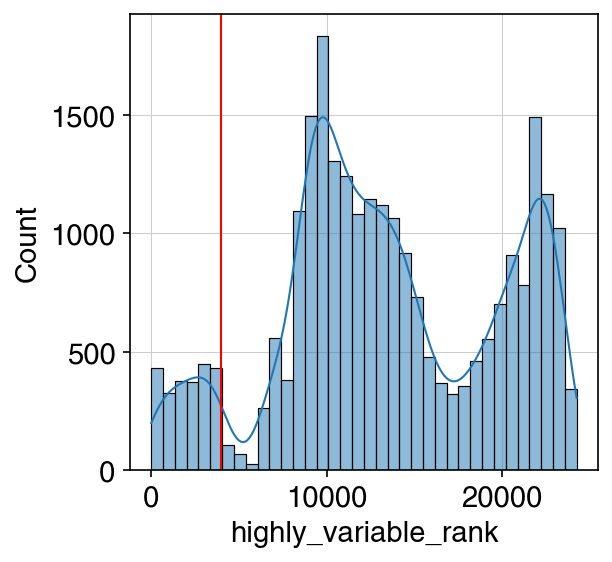

In [43]:
ax = sns.histplot(adata.var['highly_variable_rank'], kde=True)
ax.axvline(4000, c='r')

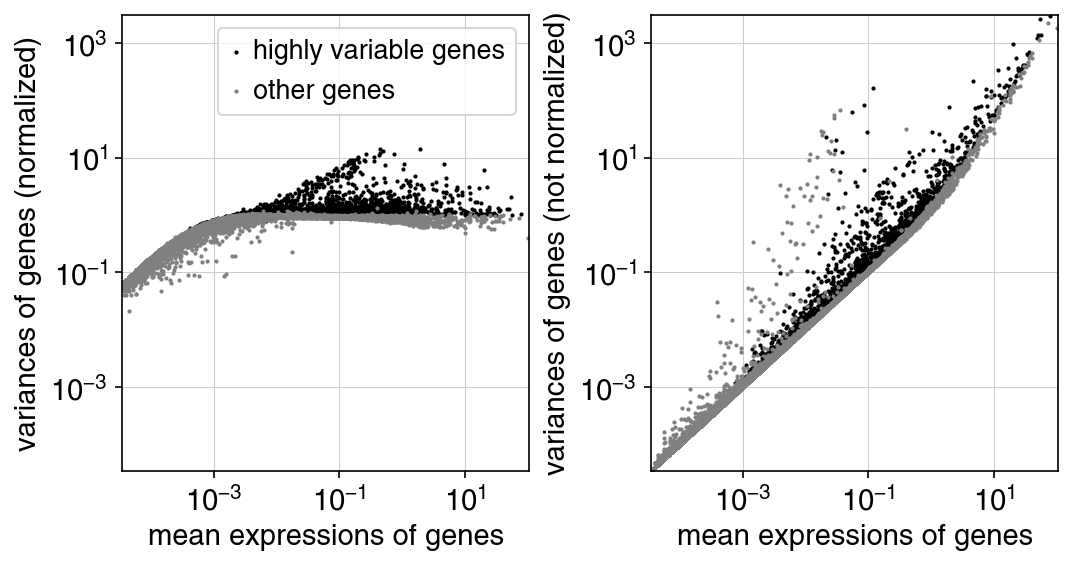

In [11]:
reselect_hvg_seurat_v3(adata.var.copy(), 4000, adata)
sc.pl.highly_variable_genes(
    adata,
    log=True
)

In [ ]:
adata_tissue = sc.read_h5ad('adata_tissue.h5ad')
adata_tissue

In [7]:
out_file = f"{work_dir}/adata_tissue_hvg.h5ad"

if os.path.exists(out_file):
    print(f"Reading {out_file}...")
    adata_tissue = sc.read(out_file)
else:
    print("Computing highly variable genes...")
    sc.pp.highly_variable_genes(
        adata_tissue,
        layer="counts",
        n_top_genes=adata_tissue.shape[1], 
        flavor="seurat_v3",
        span=1.0,
        batch_key="sample",
    )
    # Calculate Gene Expression Metrics per Sample
    exp_df = sc.get.obs_df(adata_tissue, adata_tissue.var_names.to_list(), layer="counts") 
    exp_df = (exp_df > 0.0) 
    exp_df["sample"] = adata_tissue.obs["sample"].copy()
    gene_nz_pct_per_id = exp_df.groupby("sample").mean()  
    gene_nz_pct_per_id.index.name = None
    adata_tissue.var["frac_nz_per_id_min"] = gene_nz_pct_per_id.min()
    adata_tissue.var["frac_nz_per_id_range"] = gene_nz_pct_per_id.max() - gene_nz_pct_per_id.min()
    print(f"Writing {out_file}...")
    adata_tissue.write(out_file)
    del(exp_df)

Reading adata_tissue_hvg.h5ad...


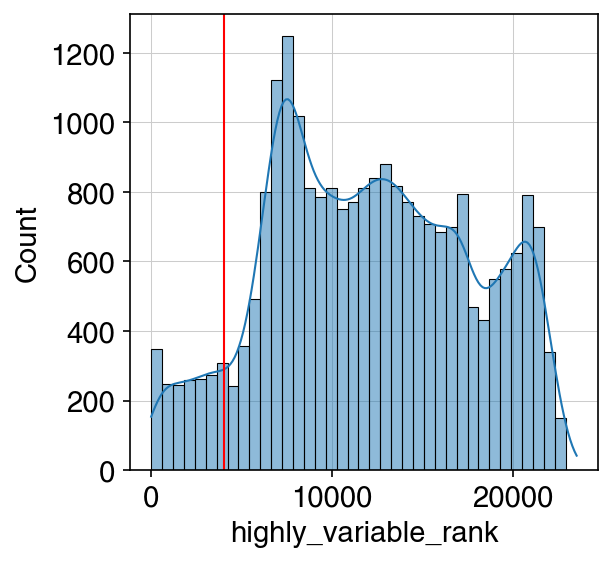

In [45]:
ax = sns.histplot(adata_tissue.var['highly_variable_rank'], kde=True)
ax.axvline(4000, c='r')

/data/conda-users/envs/ybcho/scvi_env/lib/python3.10/site-packages/scanpy/plotting/_preprocessing.py:81: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  pl.xlim(0.95 * np.min(means), 1.05 * np.max(means))


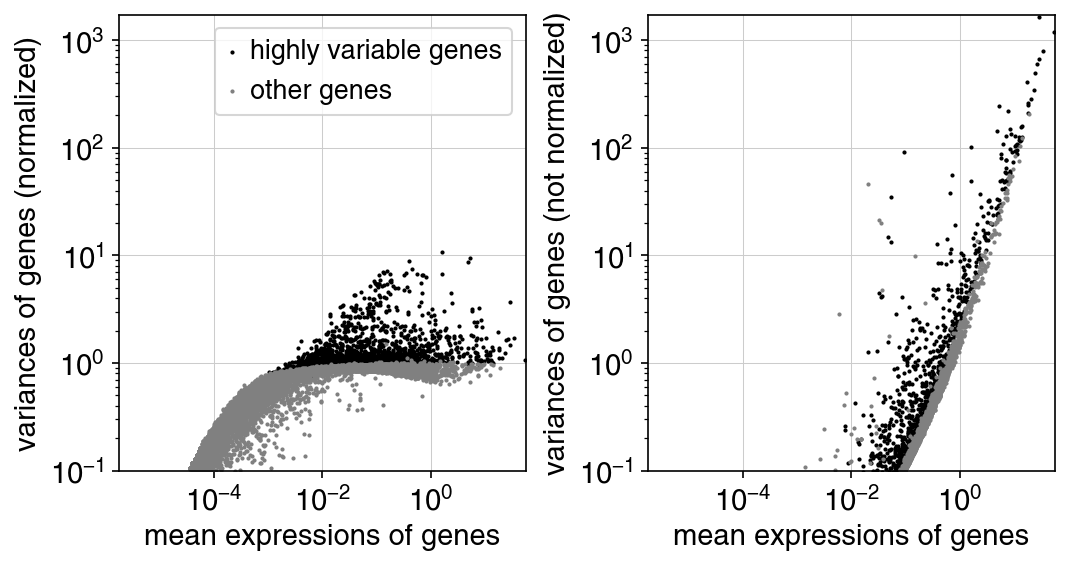

In [12]:
reselect_hvg_seurat_v3(adata_tissue.var.copy(), 4000, adata_tissue)
sc.pl.highly_variable_genes(
    adata_tissue,
    log=True
)

In [14]:
common_genes = adata_tissue.var[adata_tissue.var['highly_variable']].index.intersection(adata.var[adata.var['highly_variable']].index)
len(common_genes)

2101

In [15]:
common_genes = adata_tissue.var[adata_tissue.var['highly_variable']].index.intersection(adata.var[adata.var['highly_variable']].index)

not_in_common_genes_blood = adata.var.index.difference(common_genes)
not_in_common_genes_tissue = adata_tissue.var.index.difference(common_genes)

top_blood_genes = (
    adata.var.loc[not_in_common_genes_blood]
    .sort_values("highly_variable_rank")
    .head(1000)
    .index
)

top_tissue_genes = (
    adata_tissue.var.loc[not_in_common_genes_tissue]
    .sort_values("highly_variable_rank")
    .head(3000)
    .index
)


In [18]:
final_genes_query = (
    common_genes
    .union(top_blood_genes)
    .union(top_tissue_genes)
    .intersection(adata_tissue.var_names)
    .intersection(adata.var_names)
)
len(final_genes_query)

5980

In [19]:
adata_ref_tissue = adata_tissue[:, final_genes_query].copy()
adata_ref_tissue

AnnData object with n_obs × n_vars = 246345 × 5980
    obs: 'sample_num', 'sample', 'patient_id', 'sample_IOT_DAAN', 'disease', 'gender', 'age', 'batch', 'biopsy_site', 'tissue', 'histology', 'egfr_mutant', 'driver_oncogene', 'tumor_pdl1_expression', 'io_preorpost', 'pd_drug', 'stage_initial', 'stage', 'meta', 'chemo', 'chemo_date', 'biopsy_date', 'ctb_days', 'pfs_days', 'group1', 'group2', 'group3', 'Group1', 'Group2', 'Group3', 'Group4', 'Group5', 'mad4_prd', 'auto_prd', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'complexity', 'S_score', 'G2M_score', 'phase', 'louvain_res1', 'louvain_res2', 'scVI_pred', 'coarse_ann', 'coarse_ann_num', 'louvain_res3', 'annotation', 'umap_density_Group1', 'umap_density_Group2', 'umap_density_Group3', 'umap_density_Group4', 'umap_density_Group5', 'Naiveness_score', 'Residency_score', 'Exhaustion_score', 'Cytotoxicity_score', 'annotation

In [20]:
adata_query_blood = adata[:, final_genes_query].copy()
adata_query_blood

AnnData object with n_obs × n_vars = 272323 × 5980
    obs: 'file', 'time', 'patient', 'sample', 'response', 'age', 'sex', 'therapy', 'histology', 'mad4_prd', 'auto_prd', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'complexity', 'leiden_res2'
    var: 'mt', 'rb', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'frac_nz_per_id_min', 'frac_nz_per_id_range', 'n_cells'
    uns: 'dendrogram_leiden_res2', 'hvg', 'leiden', 'leiden_res2_colors', 'log1p', 'mad4_prd_colors', 'neighbors', 'pca', 'response_colors', 'sample_colors', 'time_colors', 'umap'
    obsm: 'X_harmony', 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts', 'logcounts'
    obsp: 'connectivities', 'distances'

## scVI

In [17]:
SCVI_LATENT_KEY = "X_scVI"

In [17]:
scvi.__version__

'1.1.5'

In [33]:
scvi.model.SCVI.setup_anndata(adata_ref_tissue, layer='counts', batch_key='sample')

In [11]:
model_path = f'{work_dir}/model'
if not os.path.exists(model_path):
    os.makedirs(model_path)

In [12]:
out_path = f'{model_path}/scvi_refmap_try04'

if os.path.exists(out_path):
    scvi_ref = scvi.model.SCVI.load(out_path)
else:
    scvi_ref = scvi.model.SCVI(adata_ref_tissue, n_hidden=128, n_layers=3, n_latent=30,
                            gene_likelihood='nb', dispersion='gene', use_layer_norm='both', use_batch_norm='none',
                            encode_covariates=True, dropout_rate=0.2)
    scvi_ref.to_device('cuda:0')
    scvi_ref.train(max_epochs=1000, batch_size=256,  
                early_stopping=True, early_stopping_patience=50, early_stopping_min_delta=1e-3)
    
    scvi_ref.save(out_path, save_anndata=True)
    
print(scvi_ref)

INFO     File /home/ybcho/Lung_Cancer_PBMC/v11_3.TNK_PP_EDA/model/scvi_refmap_try04/model.pt already downloaded    


SCVI model with the following parameters: 
n_hidden: 128, n_latent: 30, n_layers: 3, dropout_rate: 0.2, dispersion: gene, gene_likelihood: nb, 
latent_distribution: normal.
Training status: Trained
Model's adata is minified?: False

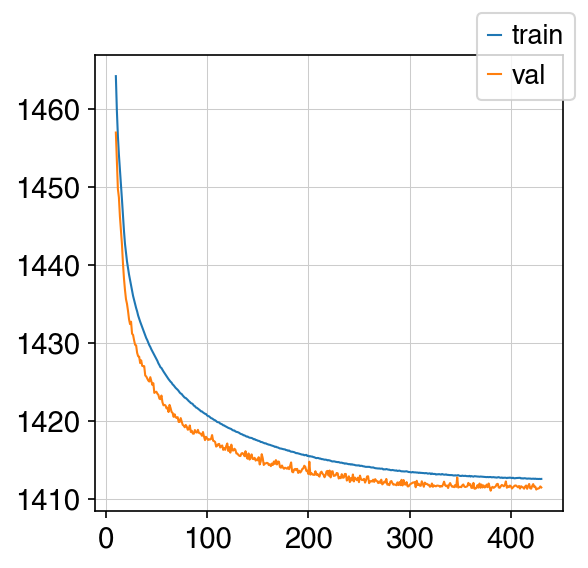

In [22]:
skip_n = 10
fig, ax = plt.subplots()
ax.plot(
    scvi_ref.history['elbo_train']['elbo_train'][skip_n:],
    label='train'
)
ax.plot(
    scvi_ref.history['elbo_validation']['elbo_validation'][skip_n:],
    label='val'
)
fig.legend()

In [13]:
adata_tissue.obsm[SCVI_LATENT_KEY] = scvi_ref.get_latent_representation()

In [26]:
sc.pp.neighbors(adata_tissue, n_neighbors=50, n_pcs=30, use_rep='X_scVI')
sc.tl.leiden(adata_tissue, key_added='leiden_res2', resolution=2.0)
sc.tl.umap(adata_tissue, min_dist=0.5, spread=1.2)

computing neighbors
    computing neighbors
    computed neighbors (0:00:44)
    computed connectivities (0:00:43)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:01:28)
computing UMAP


  0%|          | 0/200 [00:00<?, ?it/s]

	completed  0  /  200 epochs
	completed  20  /  200 epochs
	completed  40  /  200 epochs
	completed  60  /  200 epochs
	completed  80  /  200 epochs
	completed  100  /  200 epochs
	completed  120  /  200 epochs
	completed  140  /  200 epochs
	completed  160  /  200 epochs
	completed  180  /  200 epochs
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:03:04)


/data/conda-users/envs/ybcho/scvi_env/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


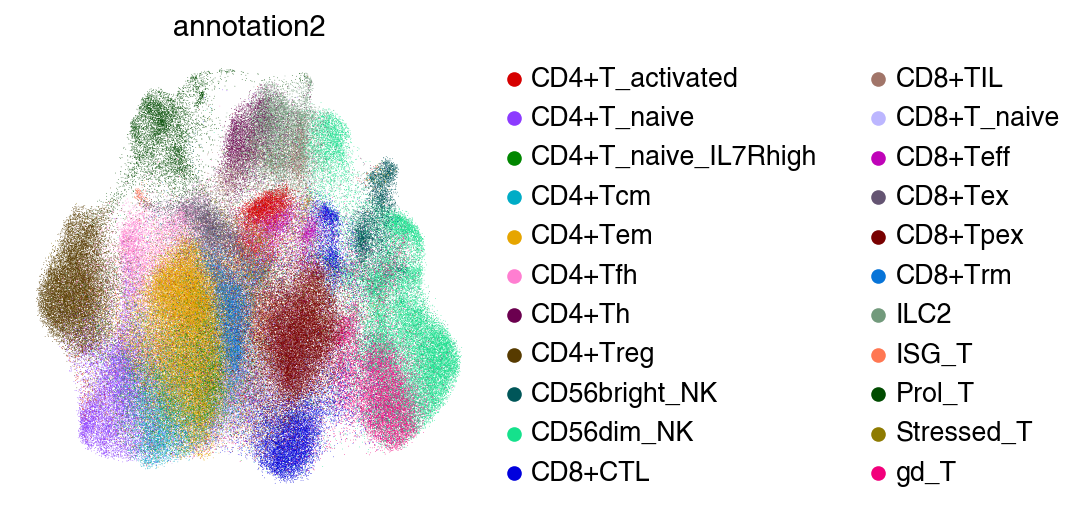

In [27]:
sc.pl.umap(adata_tissue, color='annotation2',palette=cc.glasbey_dark, frameon=False)

In [15]:
out_path = f'{work_dir}/scvi_refmap_try04_query'

if os.path.exists(out_path):
    scvi_query = scvi.model.SCVI.load(out_path)
else:
    scvi.model.SCVI.prepare_query_anndata(adata_query_blood, scvi_ref)
    scvi_query = scvi.model.SCVI.load_query_data(adata_query_blood, scvi_ref)
    scvi_query.to_device('cuda:0')  # GPU 사용
    scvi_query.train(max_epochs=300, batch_size=256, plan_kwargs={'weight_decay':0.0},
                       early_stopping=True, early_stopping_patience=50, early_stopping_min_delta=5e-1)
    
    scvi_query.save(out_path, save_anndata=True)
    
print(scvi_query)

INFO     File /home/ybcho/Lung_Cancer_PBMC/v11_3.TNK_PP_EDA/scvi_refmap_try04_query/model.pt already downloaded    


SCVI model with the following parameters: 
n_hidden: 128, n_latent: 30, n_layers: 3, dropout_rate: 0.2, dispersion: gene, gene_likelihood: nb, 
latent_distribution: normal.
Training status: Trained
Model's adata is minified?: False

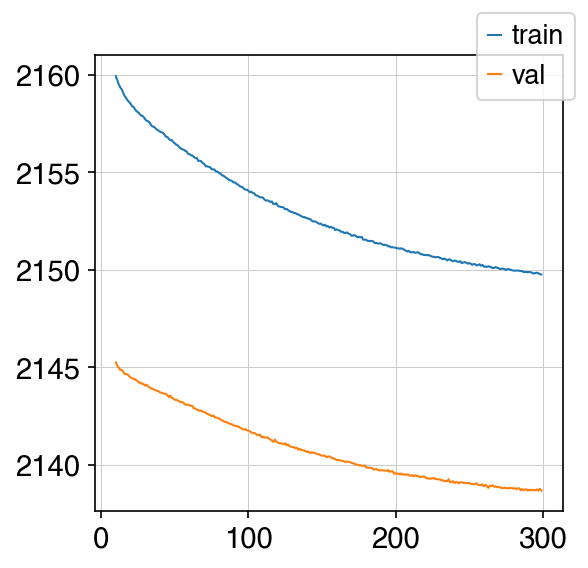

In [30]:
skip_n = 10
fig, ax = plt.subplots()
ax.plot(
    scvi_query.history['elbo_train']['elbo_train'][skip_n:],
    label='train'
)
ax.plot(
    scvi_query.history['elbo_validation']['elbo_validation'][skip_n:],
    label='val'
)
fig.legend()

In [16]:
adata.obsm[SCVI_LATENT_KEY] = scvi_query.get_latent_representation()

In [17]:
adata_tissue.obs['type'] = 'tissue'
adata.obs['type'] = 'blood'
adata_total = sc.concat([adata_tissue, adata], join='outer')

In [21]:
#adata_total.write(f'{work_dir}/scvi_refmap_try04_total.h5ad')

In [ ]:
sc.pp.neighbors(adata_total, n_neighbors=50, n_pcs=30, use_rep='X_scVI')
sc.tl.leiden(adata_total, key_added='leiden_paga', flavor='igraph', resolution=2.0)
sc.tl.paga(adata_total, groups='leiden_paga')
sc.pl.paga(adata_total, layout='fa', threshold=0.05, plot=False)
sc.tl.umap(adata_total, init_pos='paga', min_dist=0.4, spread=1.2, maxiter=300)

computing neighbors
        initialized `.distances` `.connectivities` 
    computing neighbors
    computed neighbors (0:01:51)
    computed connectivities (0:00:06)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:01:58)
running Leiden clustering
    finished: found 33 clusters and added
    'leiden_paga', the cluster labels (adata.obs, categorical) (0:01:10)
running PAGA
        initialized `.distances` `.connectivities` 
    finished: added
    'paga/connectivities', connectivities adjacency (adata.uns)
    'paga/connectivities_tree', connectivities subtree (adata.uns) (0:00:42)
--> added 'pos', the PAGA positions (adata.uns['paga'])
computing UMAP


  0%|          | 0/300 [00:00<?, ?it/s]

	completed  0  /  300 epochs
	completed  30  /  300 epochs
	completed  60  /  300 epochs
	completed  90  /  300 epochs
	completed  120  /  300 epochs
	completed  150  /  300 epochs
	completed  180  /  300 epochs
	completed  210  /  300 epochs
	completed  240  /  300 epochs
	completed  270  /  300 epochs
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:07:29)


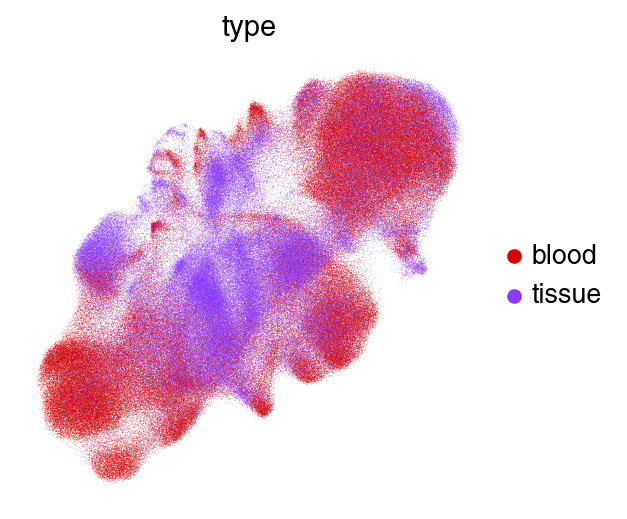

In [ ]:
sc.pl.umap(adata[adata.obs.sample(frac=1, random_state=2).index, :], color=['type'], palette=cc.glasbey_dark, frameon=False)

In [ ]:
palette_dict = {

 'CD4+T_activated': '#790000',
 'CD4+T_naive': '#0774D8',
 'CD4+Tcm': '#729A7C',
 'CD4+Tem': '#FF7752',
 'CD4+Tfh': '#004B00',
 'CD4+Th': '#8E7B01',
 'CD4+Treg': '#F2007B',
 'CD56bright_NK': '#8EBA00',
 'CD56dim_NK': '#A57BB8',
 'CD8+CTL': '#5901A3',
 'CD8+TIL': '#E2AFAF',
 'CD8+T_naive': '#A03A52',
 'CD8+Teff': '#A1C8C8',
 'CD8+Ttex': '#634049',
 'CD8+Tpex': '#FFFA17',
 'CD8+Trm': '#BAC389',
 'ILC2': '#C4668E',
 'ISG_T': '#919EB6',
 'gd_T': '#810a63ff',
 'Prol_T': '#03DAE6',
 'Stressed_T': '#93A14F',
 'CD8+CTL_TOX':'#EB523D',

 }

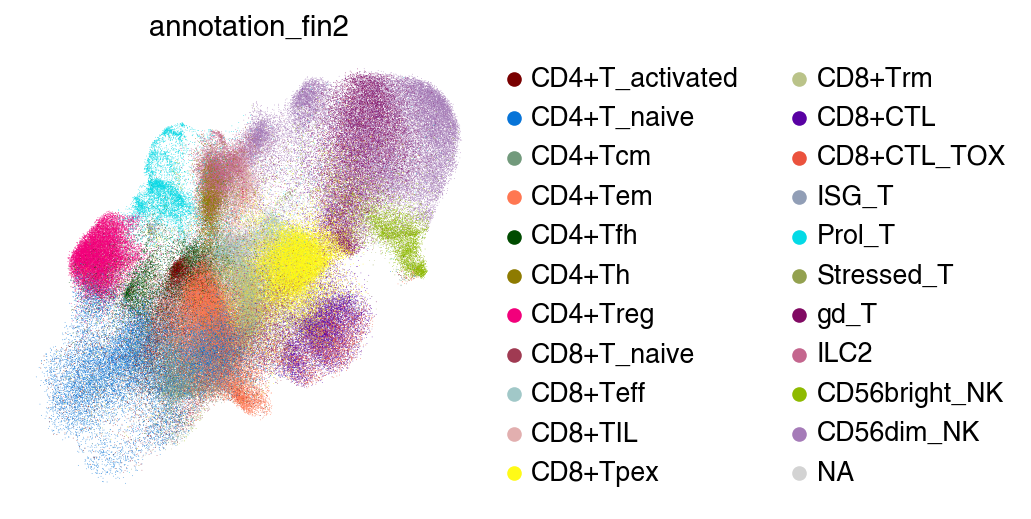

In [ ]:
sc.pl.umap(adata[adata.obs['type']=='tissue'], color=['annotation_fin2'], palette=palette_dict, frameon=False)